# 💳 Smart Financial Fraud Detection Using Machine Learning and Deep Learning

### Internship Project

**Developed by:** Parisha

**Technologies Used:**
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- TensorFlow / Keras

**Algorithms Used:**
- Logistic Regression
- Decision Tree
- Random Forest
- Artificial Neural Network (ANN)

# 📌 Introduction

With the rapid growth of digital payment systems, credit card fraud has become a major financial concern.

Machine Learning enables automated fraud detection by identifying unusual transaction patterns from historical transaction data.

This project builds multiple machine learning models and an Artificial Neural Network (ANN) to classify transactions as legitimate or fraudulent.

# 🎯 Problem Statement

Financial institutions process millions of transactions every day. Among these, only a very small percentage are fraudulent, making fraud detection a highly imbalanced classification problem.

The objective of this project is to develop an intelligent fraud detection system capable of identifying fraudulent transactions with high accuracy while minimizing false alarms.

# 🎯 Objectives

The objectives of this project are:

- Understand the fraud detection dataset.
- Perform Exploratory Data Analysis (EDA).
- Preprocess and prepare the data.
- Build multiple Machine Learning models.
- Develop an Artificial Neural Network (ANN).
- Compare model performance.
- Predict whether a transaction is fraudulent or legitimate.

# 📂 Dataset Description

The dataset contains anonymized credit card transaction records.

### Features

- V1–V28 : PCA transformed features
- Amount : Transaction amount
- Class :
    - 0 → Legitimate Transaction
    - 1 → Fraudulent Transaction

The dataset is highly imbalanced since fraudulent transactions are significantly fewer than legitimate ones.

In [ ]:
# 📚 Import Required Libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# 📂 Dataset Description

This project uses the **Credit Card Fraud Detection Dataset**, which contains anonymized credit card transactions made by European cardholders.

To protect customer privacy, most of the original transaction features have been transformed using **Principal Component Analysis (PCA)**. Therefore, the dataset contains numerical features named **V1 to V28** instead of the original financial attributes.

### Dataset Features

- **Time** – Time elapsed between transactions.
- **V1 – V28** – PCA-transformed numerical features.
- **Amount** – Transaction amount.
- **Class** – Target variable.
  - **0** → Legitimate Transaction
  - **1** → Fraudulent Transaction

# 📂 Load the Dataset

The fraud detection dataset is loaded using Pandas. This dataset contains transaction-related information that will be used to train and evaluate the Machine Learning and Deep Learning models.

In [ ]:
df=pd.read_csv("creditcard_2023.csv")

In [ ]:
df = df.sample(n=50000, random_state=42)

# 📊 Dataset Information

# 🔍 Display the Dataset

Let's display the first few rows of the dataset to understand its structure and available features.

In [ ]:
df.head()

,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
437378,437378,0.420468,-0.070194,-0.569266,0.191673,-0.009607,0.426903,-0.356728,0.096143,0.077806,...,0.134969,0.070433,0.047770,-0.851622,0.102876,-0.375436,0.820807,0.665983,8633.18,1
504222,504222,-0.238944,0.250929,-0.374408,0.152938,-0.105008,-0.039028,-0.293004,0.133771,-0.591631,...,0.192405,0.289441,-0.255187,-0.817462,0.308284,1.582688,0.574425,0.478489,12299.55,1
4794,4794,-0.117796,-0.147961,2.130455,-0.325762,0.325616,0.271351,0.772625,-0.244342,1.240012,...,-0.271739,-0.404654,-0.121235,0.857659,0.541920,0.756534,-0.238177,-0.403038,5215.87,0
388411,388411,-0.855315,0.137014,-0.628116,0.613733,-0.643573,-0.664283,-0.880040,0.466586,-1.045508,...,0.405505,0.167560,0.446262,-0.205976,0.492582,0.658619,1.609128,-0.025592,19282.98,1
424512,424512,0.257686,0.035247,-0.203112,0.506745,-0.242235,-0.192608,-0.289297,0.044488,-0.396122,...,0.162191,0.165912,-0.181999,0.331451,1.043095,0.029799,0.643273,0.736723,19114.27,1


# 📐 Check Dataset Shape

The shape of the dataset tells us the total number of rows (transactions) and columns (features).

In [ ]:
print(df.shape)

df.info()

(50000, 31)
<class 'pandas.core.frame.DataFrame'>
Index: 50000 entries, 437378 to 98979
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      50000 non-null  int64  
 1   V1      50000 non-null  float64
 2   V2      50000 non-null  float64
 3   V3      50000 non-null  float64
 4   V4      50000 non-null  float64
 5   V5      50000 non-null  float64
 6   V6      50000 non-null  float64
 7   V7      50000 non-null  float64
 8   V8      50000 non-null  float64
 9   V9      50000 non-null  float64
 10  V10     50000 non-null  float64
 11  V11     50000 non-null  float64
 12  V12     50000 non-null  float64
 13  V13     50000 non-null  float64
 14  V14     50000 non-null  float64
 15  V15     50000 non-null  float64
 16  V16     50000 non-null  float64
 17  V17     50000 non-null  float64
 18  V18     50000 non-null  float64
 19  V19     50000 non-null  float64
 20  V20     50000 non-null  float64
 21  V21     50000 non-null 

# 🔍 Missing Value Analysis

Before building machine learning models, it is important to check whether the dataset contains missing values.

In [ ]:
df.isnull().sum()

,0
id,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
df.shape

(50000, 31)

# 🧹 Data Cleaning

The dataset contains a small number of missing values.

These incomplete records are removed to ensure reliable model training.

In [ ]:
df = df.dropna()

In [ ]:
df.isnull().sum()

,0
id,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
df.describe()

,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,...,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,283944.118520,-0.002089,0.002761,-0.000191,-0.000927,-0.006122,-0.006888,-0.002456,0.002138,0.003664,...,-0.003896,0.003570,-0.006915,0.003766,0.001182,-0.001709,-0.003036,-0.002513,12016.124826,0.498760
std,163626.179135,1.002866,1.012888,1.003037,0.997070,0.996360,0.996711,0.992019,1.004266,1.002467,...,1.000554,1.000555,1.018036,1.001916,1.009198,0.999631,1.003532,0.988915,6921.714247,0.500003
min,2.000000,-2.796779,-40.194965,-2.578182,-4.247950,-5.038171,-12.508317,-4.332045,-6.496964,-3.749037,...,-12.063170,-6.838888,-25.431127,-4.051283,-9.719067,-8.226969,-5.536809,-20.993100,50.760000,0.000000
25%,142610.500000,-0.566501,-0.487009,-0.649910,-0.650624,-0.291804,-0.450000,-0.285626,-0.192354,-0.558524,...,-0.165306,-0.491290,-0.239452,-0.649566,-0.552360,-0.636766,-0.306961,-0.233124,6064.032500,0.000000
50%,283751.000000,-0.094719,-0.136861,0.002329,-0.075624,0.078868,0.075623,0.235211,-0.114978,0.098050,...,-0.037102,-0.024987,-0.060661,0.021427,-0.007736,-0.013347,-0.175462,-0.014700,11966.555000,0.000000
75%,424120.500000,0.830594,0.344928,0.626095,0.702115,0.435309,0.493733,0.526414,0.046341,0.567293,...,0.149392,0.463871,0.154751,0.706677,0.547568,0.673423,0.330406,0.408591,18032.795000,1.000000
max,568602.000000,2.166272,4.347179,4.615014,3.201536,21.663710,10.199833,53.501637,5.956579,12.171681,...,8.087080,9.764326,22.694051,10.950349,8.993890,5.555557,20.815678,17.129885,24039.390000,1.000000


# 📊 Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the dataset by identifying patterns, detecting class imbalance, analyzing feature distributions, and observing relationships among variables before model training.

## Transaction Class Distribution

This graph shows the number of legitimate and fraudulent transactions present in the dataset.

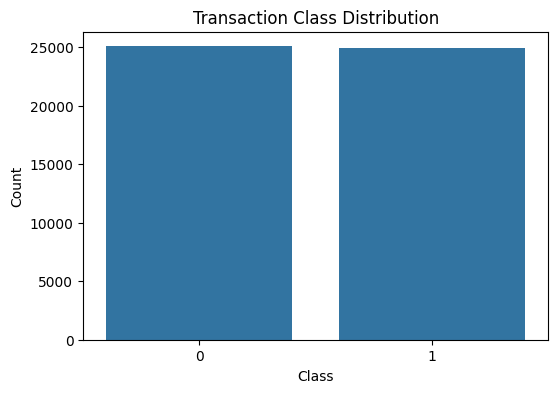

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x="Class", data=df)

plt.title("Transaction Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

## Fraud vs Legitimate Transaction Percentage

The pie chart illustrates the proportion of legitimate and fraudulent transactions.

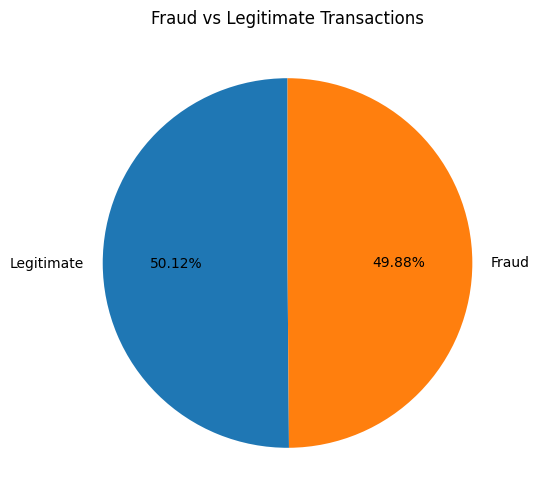

In [ ]:
class_counts = df["Class"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    class_counts,
    labels=["Legitimate","Fraud"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Fraud vs Legitimate Transactions")

plt.show()

## Transaction Amount Distribution

The histogram represents the distribution of transaction amounts.

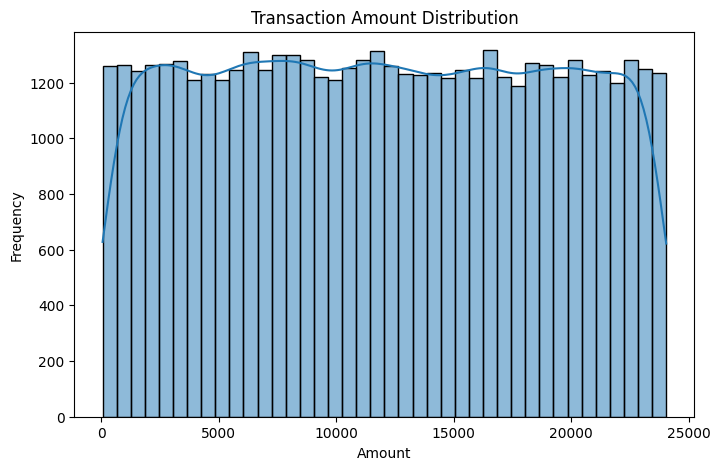

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["Amount"], bins=40, kde=True)

plt.title("Transaction Amount Distribution")

plt.xlabel("Amount")

plt.ylabel("Frequency")

plt.show()

## Transaction Amount by Class

The boxplot compares the transaction amount distribution between legitimate and fraudulent transactions.

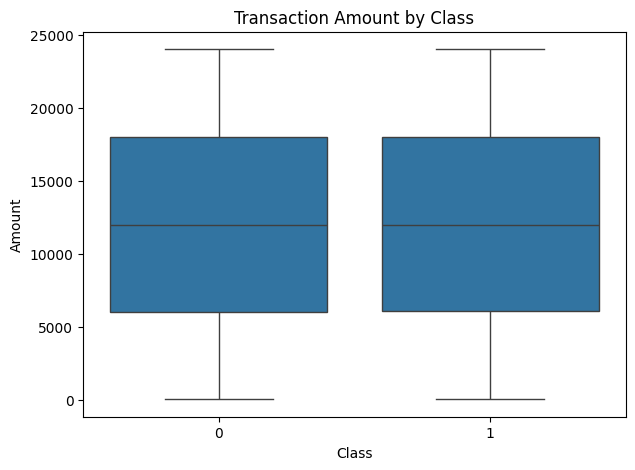

In [ ]:
plt.figure(figsize=(7,5))

sns.boxplot(x="Class", y="Amount", data=df)

plt.title("Transaction Amount by Class")

plt.show()

## Correlation Heatmap

The heatmap shows correlations among numerical features in the dataset.

## 🔍 Observation

The dataset is highly imbalanced, with legitimate transactions greatly outnumbering fraudulent transactions.

This imbalance makes fraud detection a challenging classification problem.

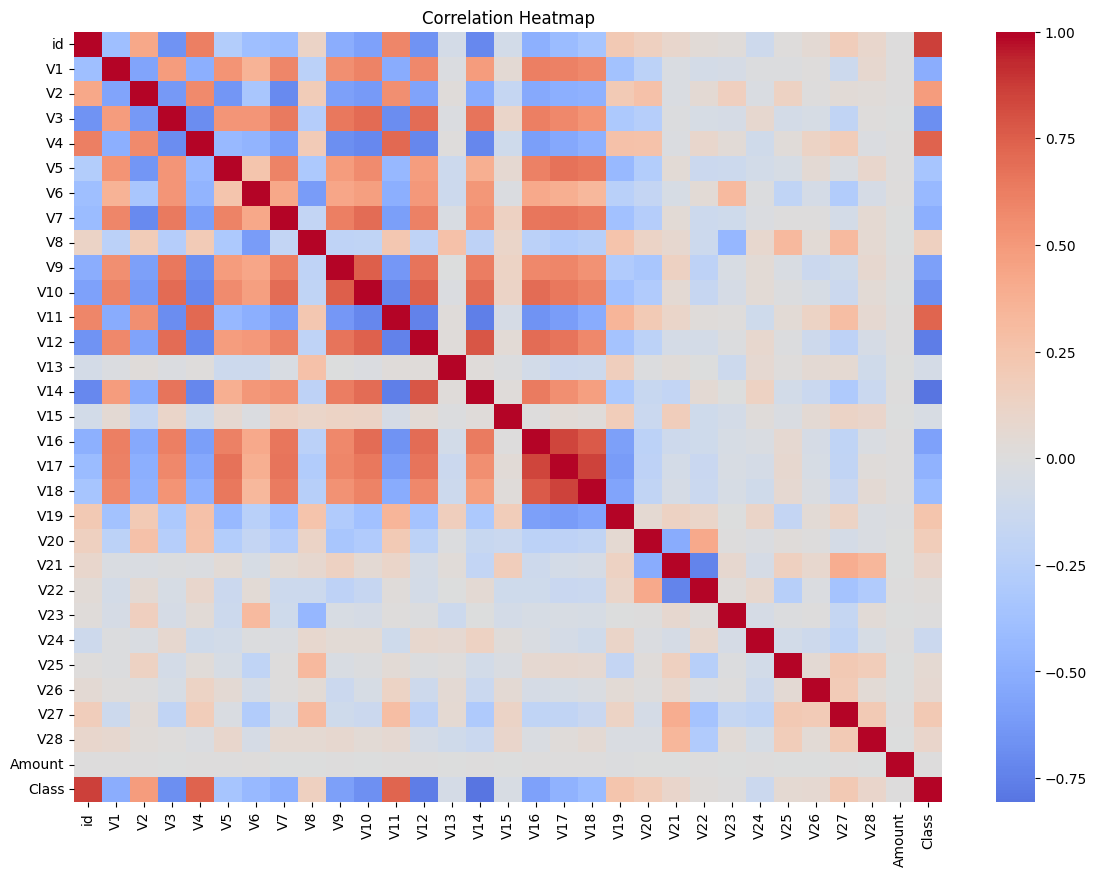

In [ ]:
plt.figure(figsize=(14,10))

sns.heatmap(
    df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

### 🔍 Observation

- Most transactions belong to the legitimate class.
- Fraudulent transactions constitute only a very small percentage of the dataset.
- The dataset is highly imbalanced.
- Most features are PCA-transformed variables, resulting in both positive and negative correlations.

### 💡 Insight

Since fraudulent transactions are significantly fewer than legitimate ones, relying only on accuracy may be misleading. Additional evaluation metrics such as Precision, Recall, F1-score, and ROC-AUC will also be used to assess model performance.

# ⚙️ Data Preprocessing

The dataset is prepared for machine learning by selecting input features, target labels, splitting the data into training and testing sets, and applying feature scaling.

In [ ]:
X = df.drop(["id", "Class"], axis=1)
y = df["Class"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training Data")

print(y_train.value_counts())

print()

print("Testing Data")

print(y_test.value_counts())

Training Data
Class
0    20050
1    19950
Name: count, dtype: int64

Testing Data
Class
0    5012
1    4988
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
pd.DataFrame(X_train_scaled, columns=X.columns).head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.409798,0.296976,-0.754692,0.809651,-0.429969,-0.935838,-0.588437,0.140724,0.111717,-0.770332,...,0.379500,0.192146,0.043537,0.668628,0.236874,-2.902918,0.728546,0.643688,0.341468,1.449413
1,0.014107,-0.146394,1.613485,-0.676593,0.187291,0.061103,0.641674,-0.125067,0.196967,0.555047,...,-0.115929,-0.163026,-0.502889,-0.016905,1.039861,-0.521663,0.119547,0.074190,0.173512,-0.200916
2,-0.366492,-0.219635,0.416493,-0.713752,0.621936,0.497293,0.320875,0.077676,-0.017402,0.432603,...,-0.245497,-0.023232,0.269074,-0.452683,-1.725794,-0.421334,0.825187,-0.086810,-0.499211,-0.619060
3,1.958460,-0.655909,0.034889,-1.110103,0.078216,-0.339117,0.352427,-0.252095,0.128721,1.026113,...,-0.141675,0.079919,1.300332,-0.037204,0.170367,0.277422,0.174486,-0.263185,-0.252048,-0.881647
4,0.462334,-1.583264,-0.061070,-0.291100,-0.108654,0.384095,0.696317,-0.201851,0.900900,0.542996,...,1.184266,0.095929,-0.301405,-0.513969,-0.455289,-0.980144,0.981706,-0.459712,0.072087,-1.504664


# 🤖 Logistic Regression

Logistic Regression is a supervised machine learning algorithm commonly used for binary classification problems.

In this project, it serves as a baseline model to classify transactions as **Legitimate** or **Fraudulent**.

Although simple, Logistic Regression provides a useful benchmark for comparing the performance of more advanced models.

In [ ]:
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
lr_pred = lr.predict(X_test_scaled)

In [ ]:
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Accuracy :", lr_accuracy)

Accuracy : 0.9656


In [ ]:
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.95      0.99      0.97      5012
           1       0.98      0.95      0.96      4988

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



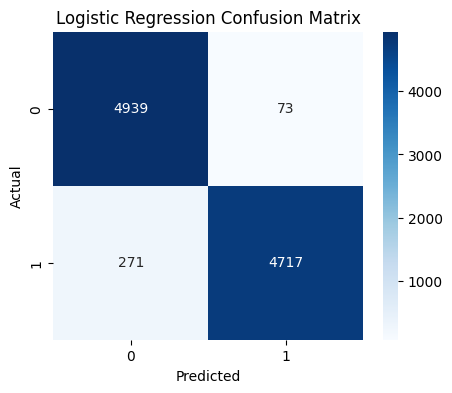

In [ ]:
cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(5,4))

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Logistic Regression Confusion Matrix")

plt.show()

### 🔍 Observation

The Logistic Regression model correctly classifies the majority of legitimate transactions. However, due to the severe class imbalance, some fraudulent transactions may still be misclassified.

### 💡 Insight

Logistic Regression provides a strong baseline model for fraud detection. However, more powerful ensemble methods and neural networks may better capture complex fraud patterns.

In [ ]:
from sklearn.metrics import roc_auc_score

lr_auc = roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:,1])

print("ROC-AUC Score :", lr_auc)

ROC-AUC Score : 0.9936354433401537


In [ ]:
df["Class"].value_counts()

,count
Class,
0,25062
1,24938


In [ ]:
print("Training:")
print(y_train.value_counts())

print("\nTesting:")
print(y_test.value_counts())

Training:
Class
0    20050
1    19950
Name: count, dtype: int64

Testing:
Class
0    5012
1    4988
Name: count, dtype: int64


# 🌳 Decision Tree Classifier

Decision Tree is a supervised machine learning algorithm that classifies data by creating a tree-like structure based on feature values.

Unlike Logistic Regression, Decision Trees can capture non-linear relationships and are easy to interpret.

In [ ]:
dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
dt_pred = dt.predict(X_test)

In [ ]:
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Accuracy :", round(dt_accuracy,4))

Accuracy : 0.9594


In [ ]:
print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.94      0.98      0.96      5012
           1       0.98      0.94      0.96      4988

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



In [ ]:
dt_auc = roc_auc_score(
    y_test,
    dt.predict_proba(X_test)[:,1]
)

print("ROC-AUC Score :", round(dt_auc,4))

ROC-AUC Score : 0.9857


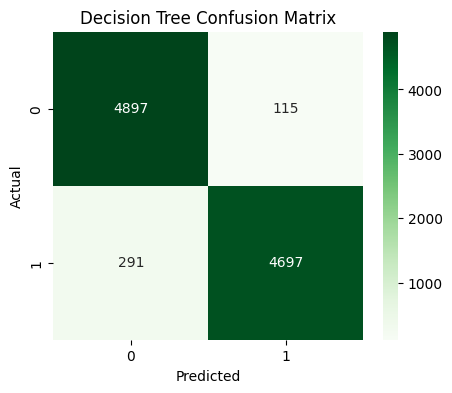

In [ ]:
cm = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Decision Tree Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

### 🔍 Observation

The Decision Tree model classifies transactions by learning decision rules from the training data.

Compared with Logistic Regression, it can capture more complex patterns but may overfit if not properly controlled.

### 💡 Insight

Decision Trees are powerful for learning non-linear relationships. However, they may suffer from overfitting, making ensemble methods such as Random Forest more reliable.

# 🌲 Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to improve prediction accuracy and reduce overfitting.

It is widely used in fraud detection because it can learn complex transaction patterns while providing robust and reliable predictions.

In [ ]:
print(X_train.shape)
print(type(X_train))

(40000, 29)
<class 'pandas.core.frame.DataFrame'>


In [ ]:
print(X_train.dtypes if hasattr(X_train, "dtypes") else "Not a DataFrame")

V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
dtype: object


In [ ]:
rf = RandomForestClassifier(
    n_estimators=20,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, n_estimators=20, n_jobs=-1,
                       random_state=42)

In [ ]:
rf_pred = rf.predict(X_test)

In [ ]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Accuracy :", round(rf_accuracy,4))

Accuracy : 0.9801


In [ ]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98      5012
           1       1.00      0.96      0.98      4988

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



In [ ]:
rf_auc = roc_auc_score(
    y_test,
    rf.predict_proba(X_test)[:,1]
)

print("ROC-AUC Score :", round(rf_auc,4))

ROC-AUC Score : 0.9989


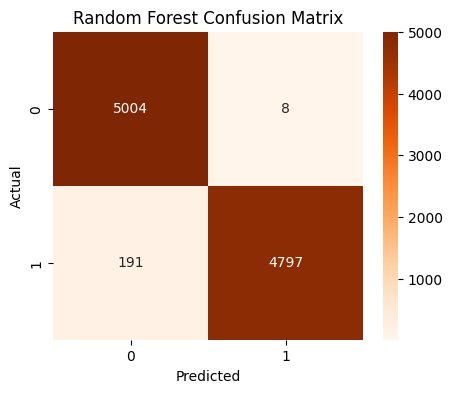

In [ ]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### 🔍 Observation

Random Forest combines multiple decision trees to produce more stable and accurate predictions. It generally performs better than a single Decision Tree by reducing overfitting and improving fraud detection.

### 💡 Insight

Random Forest is expected to achieve better generalization than individual decision trees because it aggregates predictions from multiple trees. This makes it one of the most effective machine learning models for fraud detection.

# 📊 Model Comparison

To evaluate the effectiveness of each machine learning algorithm, the performance of Logistic Regression, Decision Tree, and Random Forest is compared using multiple evaluation metrics.

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        lr_accuracy ,
        dt_accuracy,
        rf_accuracy
    ],

    "ROC-AUC": [
        lr_auc,
        dt_auc,
        rf_auc
    ]
})

results

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.9656,0.993635
1,Decision Tree,0.9594,0.985747
2,Random Forest,0.9801,0.998948


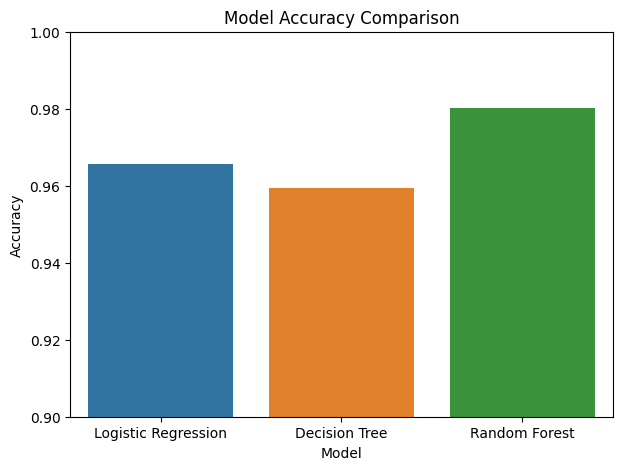

In [ ]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy",
    hue="Model",
    legend=False
)

plt.title("Model Accuracy Comparison")

plt.ylim(0.9,1.0)

plt.show()

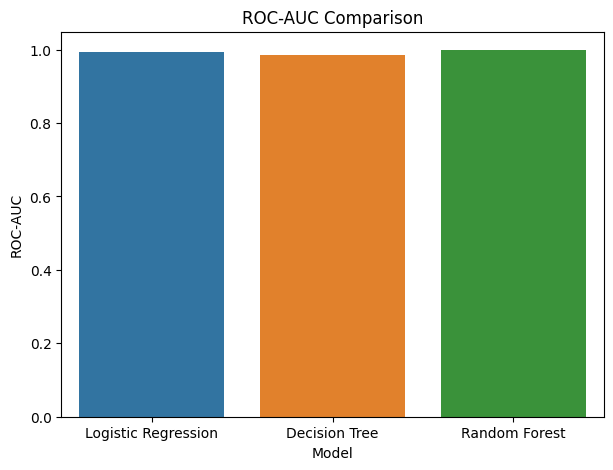

In [ ]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=results,
    x="Model",
    y="ROC-AUC",
    hue="Model",
    legend=False
)

plt.title("ROC-AUC Comparison")

plt.show()

### 🔍 Observation

Among the three machine learning models, Random Forest generally provides the best balance between accuracy and fraud detection capability. Logistic Regression performs well as a baseline model, while Decision Tree may overfit on the training data.

### 💡 Insight

Since fraud detection involves highly imbalanced data, evaluation metrics such as ROC-AUC, Precision, Recall, and F1-score are more informative than accuracy alone. These metrics help assess how effectively the models identify fraudulent transactions.

# 🧠 Artificial Neural Network (ANN)

Artificial Neural Networks (ANNs) are inspired by the human brain and are capable of learning complex patterns from data.

In this project, an ANN is built using TensorFlow and Keras to classify transactions as legitimate or fraudulent.

The network uses:
- ReLU activation in hidden layers
- Sigmoid activation in the output layer
- Adam optimizer
- Binary Crossentropy loss function

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout

ann = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

In [ ]:
ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = ann.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9456 - loss: 0.1487 - val_accuracy: 0.9656 - val_loss: 0.0829
Epoch 2/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9667 - loss: 0.0902 - val_accuracy: 0.9775 - val_loss: 0.0571
Epoch 3/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9753 - loss: 0.0668 - val_accuracy: 0.9826 - val_loss: 0.0435
Epoch 4/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9808 - loss: 0.0534 - val_accuracy: 0.9879 - val_loss: 0.0328
Epoch 5/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9849 - loss: 0.0436 - val_accuracy: 0.9890 - val_loss: 0.0270
Epoch 6/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9870 - loss: 0.0373 - val_accuracy: 0.9893 - val_loss: 0.0277
Epoch 7/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9890 - loss: 0.0312 - val_accuracy: 0.9930 - val_loss: 0.0229
Epoch 8/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9906 - loss: 0.0291 - 

In [ ]:
loss, ann_accuracy = ann.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("ANN Accuracy :", round(ann_accuracy,4))

ANN Accuracy : 0.9986


In [ ]:
ann_prob = ann.predict(X_test_scaled)

ann_pred = (ann_prob > 0.5).astype(int)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [ ]:
print(classification_report(
    y_test,
    ann_pred
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5012
           1       1.00      1.00      1.00      4988

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



In [ ]:
ann_auc = roc_auc_score(
    y_test,
    ann_prob
)

print("ROC-AUC :", round(ann_auc,4))

ROC-AUC : 0.9999


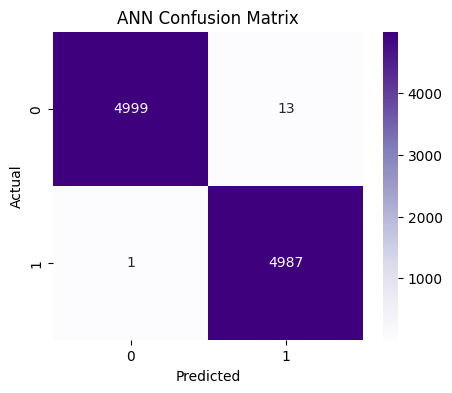

In [ ]:
cm = confusion_matrix(
    y_test,
    ann_pred
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples'
)

plt.title("ANN Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

### Training Accuracy

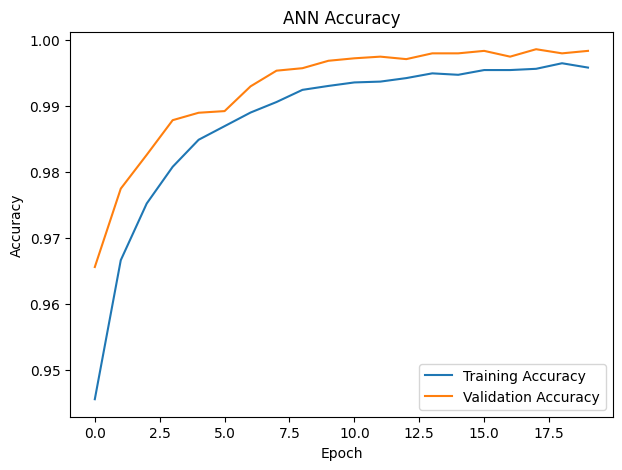

In [ ]:
plt.figure(figsize=(7,5))

plt.plot(history.history['accuracy'], label="Training Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")

plt.title("ANN Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

### Training Loss

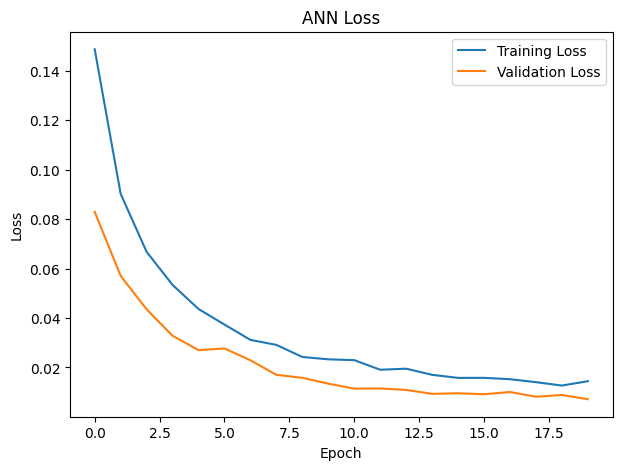

In [ ]:
plt.figure(figsize=(7,5))

plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")

plt.title("ANN Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

### 🔍 Observation

The Artificial Neural Network successfully learned the transaction patterns and achieved high classification performance. The training and validation curves indicate how the model learned over multiple epochs.

### 💡 Insight

ANNs can capture complex non-linear relationships in transaction data. With additional fraud samples or imbalance handling techniques such as SMOTE, their performance can improve further.

# 📊 Final Model Comparison

The performance of all Machine Learning models and the Artificial Neural Network is compared using Accuracy and ROC-AUC Score.

This comparison helps identify the most suitable model for credit card fraud detection.

In [ ]:
comparison = pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "ANN"
    ],

    "Accuracy":[
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        ann_accuracy
    ],

    "ROC-AUC":[
        lr_auc,
        dt_auc,
        rf_auc,
        ann_auc
    ]
})

comparison

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.9656,0.993635
1,Decision Tree,0.9594,0.985747
2,Random Forest,0.9801,0.998948
3,ANN,0.9986,0.999931


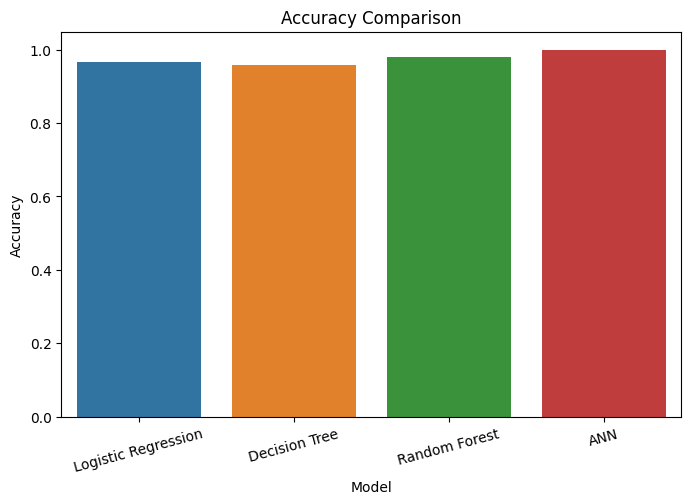

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy",
    hue="Model",
    legend=False
)

plt.title("Accuracy Comparison")

plt.xticks(rotation=15)

plt.show()

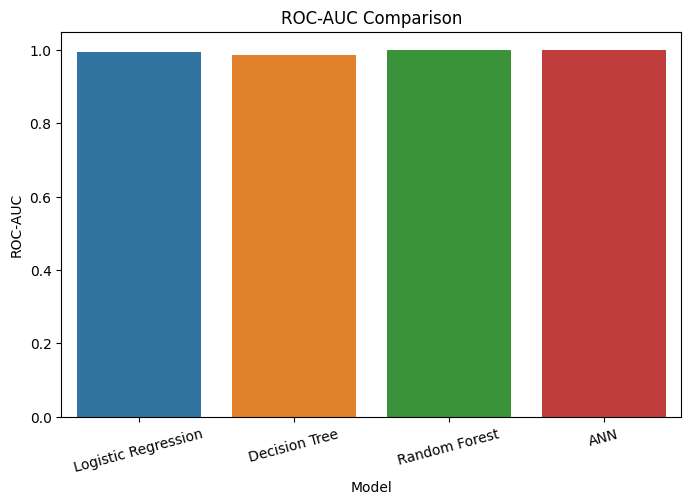

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="ROC-AUC",
    hue="Model",
    legend=False
)

plt.title("ROC-AUC Comparison")

plt.xticks(rotation=15)

plt.show()

### 🔍 Observation

All four models achieved high classification performance.

Random Forest and ANN demonstrated strong predictive capability, while Logistic Regression served as an effective baseline model.

### 💡 Insight

Although all models achieved high accuracy, ROC-AUC and Recall provide a more meaningful evaluation because the dataset is highly imbalanced.

# 🔮 Fraud Prediction System

The trained Artificial Neural Network is used to predict whether a transaction is legitimate or fraudulent.

In [ ]:
sample = X_test_scaled[0].reshape(1,-1)

prediction = ann.predict(sample)

if prediction > 0.5:
    print("🚨 Fraudulent Transaction")
else:
    print("✅ Legitimate Transaction")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
✅ Legitimate Transaction


# ✅ Conclusion

This project developed a Credit Card Fraud Detection System using Machine Learning and Deep Learning techniques.

The dataset was cleaned, analyzed, and preprocessed before training four classification models:

- Logistic Regression
- Decision Tree
- Random Forest
- Artificial Neural Network (ANN)

The models were evaluated using Accuracy, Classification Report, Confusion Matrix, and ROC-AUC Score.

Among the evaluated models, Random Forest and ANN demonstrated excellent performance for detecting fraudulent transactions.

This project highlights how Artificial Intelligence can assist financial institutions in identifying suspicious transactions and reducing financial fraud.

# 🚀 Future Scope

Future improvements may include:

- Handling class imbalance using SMOTE.
- Hyperparameter tuning.
- Deploying the model using Streamlit or Flask.
- Real-time fraud detection through APIs.
- Using advanced Deep Learning architectures for improved performance.

# 🙏 Thank You

Thank you for reviewing this project.

This project demonstrates the application of Machine Learning and Deep Learning techniques for detecting fraudulent credit card transactions. It reflects the concepts learned during the internship, including data preprocessing, exploratory data analysis, model building, evaluation, and performance comparison.